## Q1 Research - Fashion-MNIST Dropout Experiment

In [1]:
# Setup
from pathlib import Path
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import f1_score, confusion_matrix, precision_recall_fscore_support

cwd = Path.cwd()
if (cwd / "Q1" / "notebooks").exists():
    Q1_DIR = cwd / "Q1"
elif cwd.name == "Q1":
    Q1_DIR = cwd
elif cwd.name == "notebooks" and cwd.parent.name == "Q1":
    Q1_DIR = cwd.parent
else:
    raise RuntimeError("Run this notebook from Q1/notebooks, Q1, or the repository root.")

DATA_DIR = Q1_DIR / "data"
SPLIT_DIR = DATA_DIR / "split_indices"
RESULTS_DIR = Q1_DIR / "results" / "raw"
FIGURES_DIR = Q1_DIR / "figures"
CONFIG_DIR = Q1_DIR / "configs"
MODELS_DIR = Q1_DIR / "results" / "models"
for folder in (SPLIT_DIR, RESULTS_DIR, FIGURES_DIR, CONFIG_DIR, MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Device:", device)
print("PyTorch:", torch.__version__)

Device: mps
PyTorch: 2.14.0


In [2]:
# Load Fashion-MNIST training data only (official test set is reserved)
transform = transforms.ToTensor()
full_train_dataset = datasets.FashionMNIST(
    root=DATA_DIR, train=True, download=True, transform=transform
)
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]
print("Available training images:", len(full_train_dataset))

Available training images: 60000


In [3]:
# Load the Week 1 saved split indices (recreate the same seed-42 split only if absent)
train_path = SPLIT_DIR / "train_indices.npy"
val_path = SPLIT_DIR / "val_indices.npy"
if train_path.exists() and val_path.exists():
    train_indices = np.load(train_path).astype(int)
    val_indices = np.load(val_path).astype(int)
    print("Loaded Week 1 indices")
elif not train_path.exists() and not val_path.exists():
    shuffled = torch.randperm(60000, generator=torch.Generator().manual_seed(42)).numpy()
    val_indices = shuffled[:5000]
    train_indices = shuffled[5000:15000]
    np.save(train_path, train_indices)
    np.save(val_path, val_indices)
    print("Recreated and saved Week 1 seed-42 indices")
else:
    raise FileNotFoundError("One Week 1 split file is missing. Restore both files before continuing.")

assert len(train_indices) == 10000 and len(val_indices) == 5000
assert len(set(train_indices)) == 10000 and len(set(val_indices)) == 5000
assert min(train_indices.min(), val_indices.min()) >= 0
assert max(train_indices.max(), val_indices.max()) < len(full_train_dataset)
assert not set(train_indices).intersection(val_indices)

train_2000 = train_indices[:2000]   # Nested inside the 10,000 training examples
np.save(SPLIT_DIR / "train_2000_indices.npy", train_2000)
val_loader = DataLoader(Subset(full_train_dataset, val_indices.tolist()), batch_size=32)
print("Train 2,000:", len(train_2000))
print("Train 10,000:", len(train_indices))
print("Validation:", len(val_indices))
print("Overlap:", len(set(train_indices).intersection(val_indices)))

Loaded Week 1 indices
Train 2,000: 2000
Train 10,000: 10000
Validation: 5000
Overlap: 0


In [4]:
# Experiment settings from the research proposal
TRAIN_SIZES = [2000, 10000]
DROPOUT_RATES = [0.0, 0.3]
SEEDS = [42, 123, 456]
BATCH_SIZE = 32
EPOCHS = 10
SIMILAR_CLASSES = [0, 2, 4, 6]  # T-shirt/top, pullover, coat, shirt
print("Final runs:", len(TRAIN_SIZES) * len(DROPOUT_RATES) * len(SEEDS))

Final runs: 12


In [5]:
# Same Week 2 MLP architecture; dropout only changes hidden activations
class MLPClassifier(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)

print(MLPClassifier(dropout=0.0))
print("Dropout model output:", MLPClassifier(0.3)(torch.zeros(1, 1, 28, 28)).shape)

MLPClassifier(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.0, inplace=False)
    (7): Linear(in_features=64, out_features=10, bias=True)
  )
)
Dropout model output: torch.Size([1, 10])


In [6]:
# Validation accuracy, macro-F1, and predictions
loss_fn = nn.CrossEntropyLoss()

def evaluate(model):
    model.eval()
    total_loss = 0.0
    correct = 0
    true_labels, pred_labels = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * labels.size(0)
            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            true_labels.extend(labels.cpu().tolist())
            pred_labels.extend(predictions.cpu().tolist())
    y_true, y_pred = np.array(true_labels), np.array(pred_labels)
    return {
        "val_loss": total_loss / len(y_true),
        "val_accuracy": 100 * correct / len(y_true),
        "val_macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }, y_true, y_pred

In [7]:
# Train one model for a fixed number of epochs
# Same seed gives the baseline and dropout models identical initial linear weights

def train_one(train_size, dropout, seed, lr, epochs):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    model = MLPClassifier(dropout).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    train_set = Subset(full_train_dataset, train_indices[:train_size].tolist())
    loader = DataLoader(
        train_set, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(seed)
    )
    history = []
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        train_loss, train_correct = 0.0, 0
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * labels.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
        val, y_true, y_pred = evaluate(model)
        history.append({
            "epoch": epoch,
            "train_loss": train_loss / train_size,
            "train_accuracy": 100 * train_correct / train_size,
            **val
        })
    if device.type == "mps":
        torch.mps.synchronize()
    runtime = time.perf_counter() - start
    return model, pd.DataFrame(history), y_true, y_pred, runtime

In [8]:
# Small learning-rate pilot; use validation only, never the official test set
# Pilot uses the baseline at both training sizes for 2 epochs (one seed)
PILOT_LRS = [0.01, 0.05, 0.1]
pilot_rows = []
for lr in PILOT_LRS:
    for size in TRAIN_SIZES:
        _, history, _, _, runtime = train_one(size, 0.0, 42, lr, epochs=2)
        pilot_rows.append({
            "learning_rate": lr, "train_size": size,
            "val_accuracy": history.iloc[-1]["val_accuracy"],
            "val_macro_f1": history.iloc[-1]["val_macro_f1"],
            "runtime_sec": runtime
        })
        print("Pilot:", lr, "size:", size, "accuracy:", round(history.iloc[-1]["val_accuracy"], 2))
pilot_df = pd.DataFrame(pilot_rows)
pilot_df.to_csv(RESULTS_DIR / "q1_dropout_lr_pilot.csv", index=False)
selected_lr = float(pilot_df.groupby("learning_rate")["val_accuracy"].mean().idxmax())
print("Pilot-selected learning rate:", selected_lr)

Pilot: 0.01 size: 2000 accuracy: 22.56
Pilot: 0.01 size: 10000 accuracy: 63.78
Pilot: 0.05 size: 2000 accuracy: 54.56
Pilot: 0.05 size: 10000 accuracy: 75.86
Pilot: 0.1 size: 2000 accuracy: 54.98
Pilot: 0.1 size: 10000 accuracy: 75.98
Pilot-selected learning rate: 0.1


In [9]:
# Freeze settings before the 12 final runs
config_path = CONFIG_DIR / "q1_dropout_protocol.json"
protocol = {
    "dataset": "Fashion-MNIST", "architecture": [784, 128, 64, 10],
    "dropout_rates": DROPOUT_RATES, "training_sizes": TRAIN_SIZES,
    "seeds": SEEDS, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
    "optimizer": "SGD", "learning_rate": selected_lr,
    "validation_size": len(val_indices),
    "primary_metric": "validation_accuracy",
    "similar_classes": SIMILAR_CLASSES
}
if config_path.exists():
    saved_protocol = json.loads(config_path.read_text())
    if saved_protocol != protocol:
        raise ValueError("Frozen protocol already exists and differs. Check before running.")
else:
    config_path.write_text(json.dumps(protocol, indent=2))
print("Frozen protocol:", config_path)
print("Learning rate:", selected_lr)

Frozen protocol: /Users/agastyabhadani/Downloads/AI Independent Study/ai-independent-study-2026-2027/Q1/configs/q1_dropout_protocol.json
Learning rate: 0.1


In [10]:
# Run and save the 12 final experiments (safe to rerun: completed runs are skipped)
results_file = RESULTS_DIR / "q1_dropout_results.csv"
all_history_file = RESULTS_DIR / "q1_dropout_epoch_history.csv"
results = pd.read_csv(results_file) if results_file.exists() else pd.DataFrame()
all_history = pd.read_csv(all_history_file) if all_history_file.exists() else pd.DataFrame()

for size in TRAIN_SIZES:
    for dropout in DROPOUT_RATES:
        for seed in SEEDS:
            run_id = f"n{size}_drop{dropout:.1f}_seed{seed}"
            if not results.empty and run_id in results["run_id"].astype(str).values:
                print("Already done:", run_id)
                continue

            model, history, y_true, y_pred, runtime = train_one(
                size, dropout, seed, selected_lr, EPOCHS
            )
            cm = confusion_matrix(y_true, y_pred, labels=list(range(10)))
            selected_mask = np.isin(y_true, SIMILAR_CLASSES)
            similar_errors = selected_mask & np.isin(y_pred, SIMILAR_CLASSES) & (y_true != y_pred)
            within_group_rate = 100 * similar_errors.sum() / selected_mask.sum()
            row = {
                "run_id": run_id, "train_size": size, "dropout": dropout,
                "seed": seed, "learning_rate": selected_lr,
                "epochs": EPOCHS, "batch_size": BATCH_SIZE,
                "runtime_sec": runtime,
                "similar_class_confusion_pct": within_group_rate,
                **history.iloc[-1].drop("epoch").to_dict()
            }
            results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)
            results.to_csv(results_file, index=False)

            history.insert(0, "run_id", run_id)
            all_history = pd.concat([all_history, history], ignore_index=True)
            all_history.to_csv(all_history_file, index=False)
            np.savez_compressed(RESULTS_DIR / f"{run_id}_predictions.npz",
                                y_true=y_true, y_pred=y_pred, confusion=cm)
            p, r, f1, support = precision_recall_fscore_support(
                y_true, y_pred, labels=list(range(10)), zero_division=0
            )
            pd.DataFrame({"class": class_names, "precision": p, "recall": r,
                          "f1": f1, "support": support}).to_csv(
                              RESULTS_DIR / f"{run_id}_class_metrics.csv", index=False
                          )
            torch.save(model.state_dict(), MODELS_DIR / f"{run_id}.pt")
            print("Finished:", run_id, "accuracy:", round(row["val_accuracy"], 2))

print("Saved runs:", len(results), "/ 12")
print(results[["run_id", "val_accuracy", "val_macro_f1", "similar_class_confusion_pct"]])

Finished: n2000_drop0.0_seed42 accuracy: 77.5
Finished: n2000_drop0.0_seed123 accuracy: 76.16
Finished: n2000_drop0.0_seed456 accuracy: 79.84
Finished: n2000_drop0.3_seed42 accuracy: 76.76
Finished: n2000_drop0.3_seed123 accuracy: 76.02
Finished: n2000_drop0.3_seed456 accuracy: 77.4
Finished: n10000_drop0.0_seed42 accuracy: 81.28
Finished: n10000_drop0.0_seed123 accuracy: 84.4
Finished: n10000_drop0.0_seed456 accuracy: 84.34
Finished: n10000_drop0.3_seed42 accuracy: 81.14
Finished: n10000_drop0.3_seed123 accuracy: 83.74
Finished: n10000_drop0.3_seed456 accuracy: 83.74
Saved runs: 12 / 12
                    run_id  val_accuracy  val_macro_f1  \
0     n2000_drop0.0_seed42         77.50      0.779526   
1    n2000_drop0.0_seed123         76.16      0.759093   
2    n2000_drop0.0_seed456         79.84      0.802401   
3     n2000_drop0.3_seed42         76.76      0.768664   
4    n2000_drop0.3_seed123         76.02      0.750768   
5    n2000_drop0.3_seed456         77.40      0.772162   

In [11]:
# Compare average accuracy and similar-category errors across three seeds
results = pd.read_csv(RESULTS_DIR / "q1_dropout_results.csv")
summary = results.groupby(["train_size", "dropout"], as_index=False).agg(
    runs=("seed", "count"),
    accuracy_mean=("val_accuracy", "mean"),
    accuracy_std=("val_accuracy", "std"),
    macro_f1_mean=("val_macro_f1", "mean"),
    similar_confusion_mean=("similar_class_confusion_pct", "mean")
)
print(summary.round(3).to_string(index=False))
summary.to_csv(RESULTS_DIR / "q1_dropout_summary.csv", index=False)

 train_size  dropout  runs  accuracy_mean  accuracy_std  macro_f1_mean  similar_confusion_mean
       2000      0.0     3         77.833         1.863          0.780                  31.380
       2000      0.3     3         76.727         0.691          0.764                  34.334
      10000      0.0     3         83.340         1.784          0.835                  25.440
      10000      0.3     3         82.873         1.501          0.828                  25.876


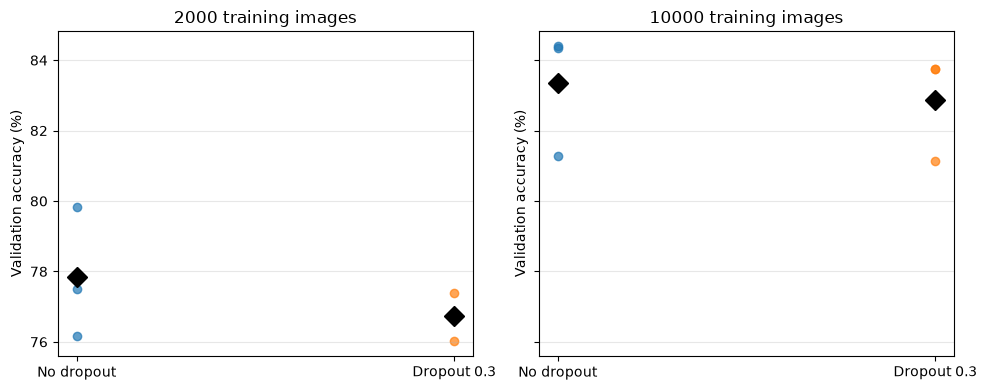

In [12]:
# Validation accuracy: show each seed and the mean
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, size in zip(axes, TRAIN_SIZES):
    group = results[results["train_size"] == size]
    for i, dropout in enumerate(DROPOUT_RATES):
        scores = group[group["dropout"] == dropout]["val_accuracy"].to_numpy()
        ax.scatter([i] * len(scores), scores, alpha=0.7)
        ax.plot(i, scores.mean(), marker="D", markersize=10, color="black")
    ax.set_xticks([0, 1], ["No dropout", "Dropout 0.3"])
    ax.set_title(f"{size} training images")
    ax.set_ylabel("Validation accuracy (%)")
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "q1_dropout_accuracy.png", dpi=160)
plt.show()

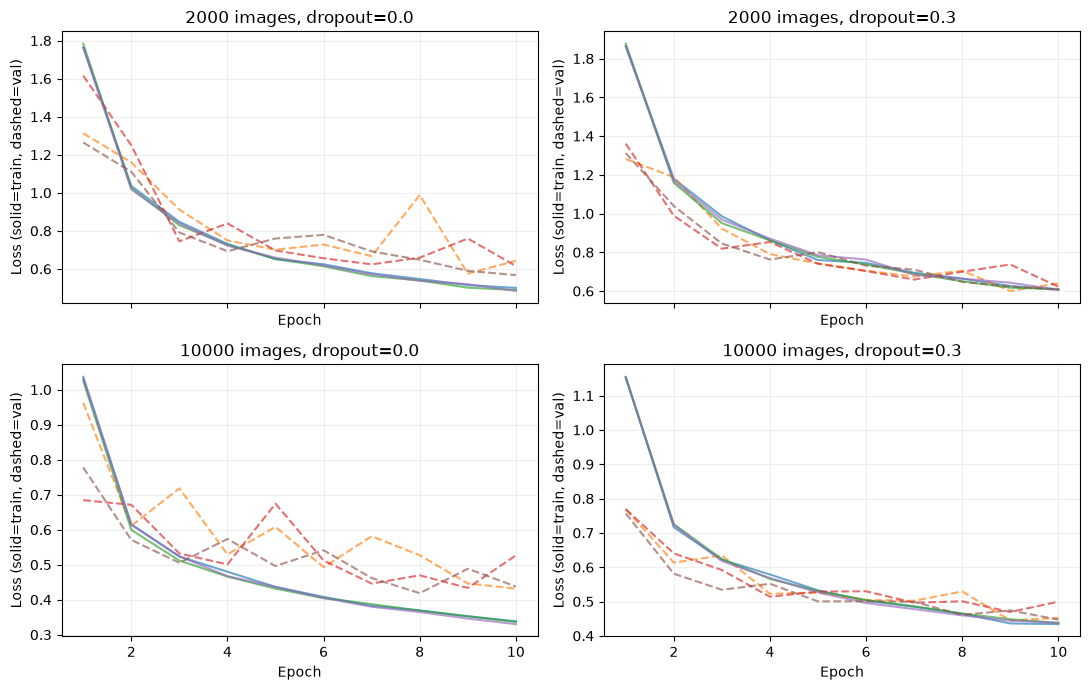

In [13]:
# Training / validation loss curves for each seed
history = pd.read_csv(RESULTS_DIR / "q1_dropout_epoch_history.csv")
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, size, dropout in zip(axes.flat,
                             [2000, 2000, 10000, 10000],
                             [0.0, 0.3, 0.0, 0.3]):
    group = history[(history["run_id"].str.startswith(f"n{size}_")) &
                    (history["run_id"].str.contains(f"drop{dropout:.1f}_", regex=False))]
    for run_id, run in group.groupby("run_id"):
        ax.plot(run["epoch"], run["train_loss"], alpha=0.65)
        ax.plot(run["epoch"], run["val_loss"], linestyle="--", alpha=0.65)
    ax.set_title(f"{size} images, dropout={dropout}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss (solid=train, dashed=val)")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "q1_dropout_loss_curves.png", dpi=160)
plt.show()

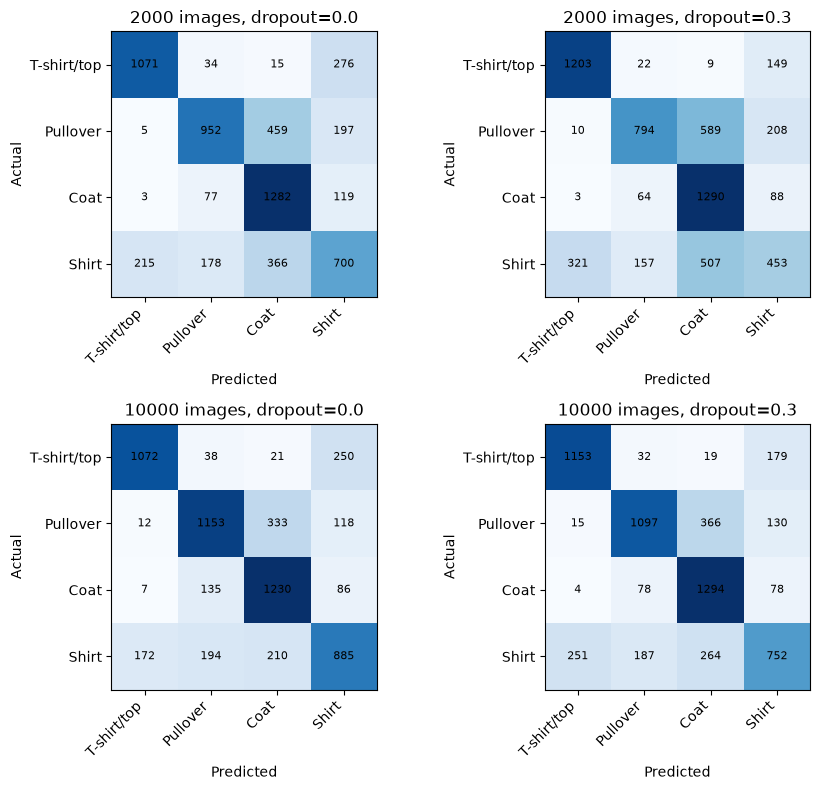

In [14]:
# Confusion matrices for T-shirts, pullovers, coats, and shirts
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (size, dropout) in zip(axes.flat,
                              [(2000, 0.0), (2000, 0.3), (10000, 0.0), (10000, 0.3)]):
    cm_total = np.zeros((10, 10), dtype=int)
    for seed in SEEDS:
        run_id = f"n{size}_drop{dropout:.1f}_seed{seed}"
        saved = np.load(RESULTS_DIR / f"{run_id}_predictions.npz")
        cm_total += saved["confusion"]
    submatrix = cm_total[np.ix_(SIMILAR_CLASSES, SIMILAR_CLASSES)]
    ax.imshow(submatrix, cmap="Blues")
    ax.set_title(f"{size} images, dropout={dropout}")
    ax.set_xticks(range(4), [class_names[i] for i in SIMILAR_CLASSES], rotation=45, ha="right")
    ax.set_yticks(range(4), [class_names[i] for i in SIMILAR_CLASSES])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    for row in range(4):
        for col in range(4):
            ax.text(col, row, submatrix[row, col], ha="center", va="center", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "q1_dropout_similar_classes.png", dpi=160)
plt.show()

In [15]:
# Save research files and record package versions
versions = {
    "python_pytorch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "torchvision": __import__("torchvision").__version__,
    "sklearn": __import__("sklearn").__version__,
    "device": str(device)
}
(CONFIG_DIR / "q1_dropout_environment.json").write_text(json.dumps(versions, indent=2))
print("Results:", RESULTS_DIR / "q1_dropout_results.csv")
print("Epochs:", RESULTS_DIR / "q1_dropout_epoch_history.csv")
print("Figures:", FIGURES_DIR)
print("Protocol:", config_path)
print("Methods paper: write from your actual protocol and saved results")

Results: /Users/agastyabhadani/Downloads/AI Independent Study/ai-independent-study-2026-2027/Q1/results/raw/q1_dropout_results.csv
Epochs: /Users/agastyabhadani/Downloads/AI Independent Study/ai-independent-study-2026-2027/Q1/results/raw/q1_dropout_epoch_history.csv
Figures: /Users/agastyabhadani/Downloads/AI Independent Study/ai-independent-study-2026-2027/Q1/figures
Protocol: /Users/agastyabhadani/Downloads/AI Independent Study/ai-independent-study-2026-2027/Q1/configs/q1_dropout_protocol.json
Methods paper: write from your actual protocol and saved results
